In [1]:
print("¡Proyecto ETL de Food Delivery iniciado!")
print("Python está listo para trabajar.")

¡Proyecto ETL de Food Delivery iniciado!
Python está listo para trabajar.


In [2]:
import sys
!"{sys.executable}" -m pip install pandas numpy matplotlib seaborn jupyter ipykernel

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("¡Librerías listas para el proyecto!")

Matplotlib is building the font cache; this may take a moment.


Pandas: 3.0.6
NumPy: 2.5.3
¡Librerías listas para el proyecto!


In [4]:
from pathlib import Path

# Ruta de la carpeta de datos
RUTA_DATA = Path("Data")

# Verificar que la carpeta exista
print("¿Existe la carpeta Data?:", RUTA_DATA.exists())

# Mostrar los archivos encontrados
for archivo in sorted(RUTA_DATA.glob("*")):
    print(f"{archivo.name} — {archivo.stat().st_size / (1024**2):.2f} MB")

¿Existe la carpeta Data?: True
restaurant_menus_parte_1.csv — 12.67 MB
restaurant_menus_parte_10.csv — 11.41 MB
restaurant_menus_parte_2.csv — 11.90 MB
restaurant_menus_parte_3.csv — 14.09 MB
restaurant_menus_parte_4.csv — 16.30 MB
restaurant_menus_parte_5.csv — 18.42 MB
restaurant_menus_parte_6.csv — 17.48 MB
restaurant_menus_parte_7.csv — 16.30 MB
restaurant_menus_parte_8.csv — 17.57 MB
restaurant_menus_parte_9.csv — 10.07 MB
restaurants.csv — 9.54 MB


In [5]:
import pandas as pd
from pathlib import Path

# 1. Cargar el catálogo de restaurantes
df_restaurantes = pd.read_csv(
    RUTA_DATA / "restaurants.csv",
    low_memory=False
)

# 2. Revisar dimensiones y columnas
print("DIMENSIONES DE RESTAURANTES")
print(f"Filas: {df_restaurantes.shape[0]:,}")
print(f"Columnas: {df_restaurantes.shape[1]}")

print("\nCOLUMNAS DISPONIBLES")
print(df_restaurantes.columns.tolist())

print("\nPRIMERAS 5 FILAS")
display(df_restaurantes.head())

print("\nVALORES NULOS POR COLUMNA")
display(
    df_restaurantes.isnull()
    .sum()
    .sort_values(ascending=False)
    .head(15)
)


DIMENSIONES DE RESTAURANTES
Filas: 63,469
Columnas: 11

COLUMNAS DISPONIBLES
['id', 'position', 'name', 'score', 'ratings', 'category', 'price_range', 'full_address', 'zip_code', 'lat', 'lng']

PRIMERAS 5 FILAS


,id,position,name,score,ratings,category,price_range,full_address,zip_code,lat,lng
0,1,19,PJ Fresh (224 Daniel Payne Drive),NaN,NaN,"Burgers, American, Sandwiches",$,"224 Daniel Payne Drive, Birmingham, AL, 35207",35207,33.562365,-86.830703
1,2,9,J' ti`'z Smoothie-N-Coffee Bar,NaN,NaN,"Coffee and Tea, Breakfast and Brunch, Bubble Tea",NaN,"1521 Pinson Valley Parkway, Birmingham, AL, 35217",35217,33.583640,-86.773330
2,3,6,Philly Fresh Cheesesteaks (541-B Graymont Ave),NaN,NaN,"American, Cheesesteak, Sandwiches, Alcohol",$,"541-B Graymont Ave, Birmingham, AL, 35204",35204,33.509800,-86.854640
3,4,17,Papa Murphy's (1580 Montgomery Highway),NaN,NaN,Pizza,$,"1580 Montgomery Highway, Hoover, AL, 35226",35226,33.404439,-86.806614
4,5,162,Nelson Brothers Cafe (17th St N),4.7,22.0,"Breakfast and Brunch, Burgers, Sandwiches",NaN,"314 17th St N, Birmingham, AL, 35203",35203,33.514730,-86.811700



VALORES NULOS POR COLUMNA


score           28167
ratings         28167
price_range     10617
zip_code          517
full_address      453
category           85
id                  0
name                0
position            0
lat                 0
lng                 0
dtype: int64

In [6]:
# Identificar los archivos de menús
archivos_menus = sorted(
    RUTA_DATA.glob("restaurant_menus_parte_*.csv"),
    key=lambda archivo: int(archivo.stem.split("_")[-1])
)

print("Cantidad de archivos encontrados:", len(archivos_menus))

# Revisar las columnas y las primeras filas de cada archivo
for archivo in archivos_menus:
    muestra = pd.read_csv(archivo, nrows=3)

    print(f"\nArchivo: {archivo.name}")
    print("Columnas:", muestra.columns.tolist())
    display(muestra.head(2))

Cantidad de archivos encontrados: 10

Archivo: restaurant_menus_parte_1.csv
Columnas: ['restaurant_id', 'category', 'name', 'description', 'price']


,restaurant_id,category,name,description,price
0,1,Extra Large Pizza,Extra Large Meat Lovers,Whole pie.,15.99 USD
1,1,Extra Large Pizza,Extra Large Supreme,Whole pie.,15.99 USD



Archivo: restaurant_menus_parte_2.csv
Columnas: ['restaurant_id', 'category', 'name', 'description', 'price']


,restaurant_id,category,name,description,price
0,1138,Sandwiches,Filet of Salmon Sandwich,"Comes with your choice of french fries, fresh ...",13.0 USD
1,1138,Burgers,Hamburger,Hamburgers are one-half pound served medium on...,9.0 USD



Archivo: restaurant_menus_parte_3.csv
Columnas: ['restaurant_id', 'category', 'name', 'description', 'price']


...

,restaurant_id,category,name,description,price
0,6886,Sexual Health,Aftera Levonorgestrel Tablet,HSA/FSA EligibleNDC 51285-100-88Emergency Cont...,39.99 USD
1,6886,Sexual Health,"Trojan Ultra Thin Lubricated Condoms, 36CT",HSA/FSA EligibleFor ultra sensitivityAmerica's...,30.49 USD



Archivo: restaurant_menus_parte_9.csv
Columnas: ['restaurant_id', 'category', 'name', 'description', 'price']


,restaurant_id,category,name,description,price
0,7810,"Pizza By The Slice (6"" hot sandwich if we run ...",Cheese Slice,A gaint slice of pizza with Sorelli Pizza sauc...,10.0 USD
1,7810,"Pizza By The Slice (6"" hot sandwich if we run ...",Pepperoni Slice,A giant slice of pizza with Sorelli Pizza sauc...,11.0 USD



Archivo: restaurant_menus_parte_10.csv
Columnas: ['restaurant_id', 'category', 'name', 'description', 'price']


,restaurant_id,category,name,description,price
0,8984,Sandwiches,Black Forest Ham 6 Inch Regular Sub,Our Black Forest Ham sandwich is a true classi...,6.39 USD
1,8984,Sandwiches,Black Forest Ham Footlong Regular Sub,Our Black Forest Ham sandwich is a true classi...,9.59 USD


## 3. Integración de los archivos de menús

En esta etapa se consolidarán los diez archivos CSV de menús
en una sola tabla, conservando sus columnas originales.

In [7]:
# Unir los diez archivos de menús

lista_menus = []

for archivo in archivos_menus:
    df_parte = pd.read_csv(archivo, low_memory=False)
    lista_menus.append(df_parte)

df_menus = pd.concat(lista_menus, ignore_index=True)

print("UNIÓN DE ARCHIVOS COMPLETADA")
print(f"Archivos procesados: {len(archivos_menus):,}")
print(f"Total de filas: {len(df_menus):,}")
print(f"Total de columnas: {df_menus.shape[1]}")

display(df_menus.head())

UNIÓN DE ARCHIVOS COMPLETADA
Archivos procesados: 10
Total de filas: 836,350
Total de columnas: 5


,restaurant_id,category,name,description,price
0,1,Extra Large Pizza,Extra Large Meat Lovers,Whole pie.,15.99 USD
1,1,Extra Large Pizza,Extra Large Supreme,Whole pie.,15.99 USD
2,1,Extra Large Pizza,Extra Large Pepperoni,Whole pie.,14.99 USD
3,1,Extra Large Pizza,Extra Large BBQ Chicken &amp; Bacon,Whole Pie,15.99 USD
4,1,Extra Large Pizza,Extra Large 5 Cheese,Whole pie.,14.99 USD


## 4. Limpieza y transformación de datos

Se revisarán los valores faltantes, los espacios innecesarios y el formato de los precios para preparar los datos para su análisis.

In [8]:
# Crear una copia para conservar los datos originales
df_menus_limpio = df_menus.copy()

# Limpiar espacios al inicio y al final de los textos
columnas_texto = ["category", "name", "description", "price"]

for columna in columnas_texto:
    df_menus_limpio[columna] = (
        df_menus_limpio[columna]
        .astype("string")
        .str.strip()
    )

# Convertir textos vacíos en valores nulos
df_menus_limpio[columnas_texto] = (
    df_menus_limpio[columnas_texto].replace("", pd.NA)
)

# Revisar los resultados de la limpieza
print("FILAS ANTES DE LA LIMPIEZA:", len(df_menus))
print("FILAS DESPUÉS DE LA LIMPIEZA:", len(df_menus_limpio))

print("\nVALORES NULOS POR COLUMNA")
display(df_menus_limpio.isna().sum())

print("\nMUESTRA DE DATOS LIMPIOS")
display(df_menus_limpio.head())


FILAS ANTES DE LA LIMPIEZA: 836350
FILAS DESPUÉS DE LA LIMPIEZA: 836350

VALORES NULOS POR COLUMNA


restaurant_id         0
category              0
name                  1
description      200451
price                 0
dtype: int64


MUESTRA DE DATOS LIMPIOS


,restaurant_id,category,name,description,price
0,1,Extra Large Pizza,Extra Large Meat Lovers,Whole pie.,15.99 USD
1,1,Extra Large Pizza,Extra Large Supreme,Whole pie.,15.99 USD
2,1,Extra Large Pizza,Extra Large Pepperoni,Whole pie.,14.99 USD
3,1,Extra Large Pizza,Extra Large BBQ Chicken &amp; Bacon,Whole Pie,15.99 USD
4,1,Extra Large Pizza,Extra Large 5 Cheese,Whole pie.,14.99 USD


## 5. Estandarización de precios

Se extraerá el importe de la columna de precios y se convertirá a formato numérico para facilitar el análisis estadístico.

In [9]:
# Extraer el importe numérico de cada precio
df_menus_limpio["price_usd"] = pd.to_numeric(
    df_menus_limpio["price"]
    .str.replace(r"[^0-9.]", "", regex=True),
    errors="coerce"
)

print("PRECIOS ANTES DE LA TRANSFORMACIÓN")
display(df_menus_limpio[["price", "price_usd"]].head(10))

print("\nESTADÍSTICAS DE PRECIOS")
display(df_menus_limpio["price_usd"].describe())

print("\nPRECIOS NO CONVERTIDOS:", df_menus_limpio["price_usd"].isna().sum())


PRECIOS ANTES DE LA TRANSFORMACIÓN


,price,price_usd
0,15.99 USD,15.99
1,15.99 USD,15.99
2,14.99 USD,14.99
3,15.99 USD,15.99
4,14.99 USD,14.99
5,3.99 USD,3.99
6,3.99 USD,3.99
7,3.99 USD,3.99
8,3.99 USD,3.99
9,3.99 USD,3.99



ESTADÍSTICAS DE PRECIOS


count     836350.0
mean      9.899058
std      11.534349
min            0.0
25%           3.95
50%           7.99
75%          12.99
max        1099.99
Name: price_usd, dtype: Float64


PRECIOS NO CONVERTIDOS: 0


## 6. Limpieza de la tabla de restaurantes

Se revisarán los datos faltantes, los formatos de texto y los identificadores de los restaurantes antes de integrar las tablas.

In [10]:
# Crear una copia para conservar los datos originales
df_restaurantes_limpio = df_restaurantes.copy()

# Limpiar espacios en las columnas de texto
columnas_texto_rest = [
    "name", "category", "price_range",
    "full_address", "zip_code"
]

for columna in columnas_texto_rest:
    df_restaurantes_limpio[columna] = (
        df_restaurantes_limpio[columna]
        .astype("string")
        .str.strip()
    )

# Convertir textos vacíos en valores nulos
df_restaurantes_limpio[columnas_texto_rest] = (
    df_restaurantes_limpio[columnas_texto_rest]
    .replace("", pd.NA)
)

# Revisar duplicados y valores faltantes
print("FILAS DE RESTAURANTES:", len(df_restaurantes_limpio))
print("IDENTIFICADORES DUPLICADOS:",
      df_restaurantes_limpio["id"].duplicated().sum())

print("\nVALORES NULOS POR COLUMNA")
display(
    df_restaurantes_limpio.isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nMUESTRA DE RESTAURANTES LIMPIOS")
display(df_restaurantes_limpio.head())


FILAS DE RESTAURANTES: 63469
IDENTIFICADORES DUPLICADOS: 0

VALORES NULOS POR COLUMNA


score           28167
ratings         28167
price_range     10617
zip_code          517
full_address      453
category           85
id                  0
name                0
position            0
lat                 0
lng                 0
dtype: int64


MUESTRA DE RESTAURANTES LIMPIOS


,id,position,name,score,ratings,category,price_range,full_address,zip_code,lat,lng
0,1,19,PJ Fresh (224 Daniel Payne Drive),NaN,NaN,"Burgers, American, Sandwiches",$,"224 Daniel Payne Drive, Birmingham, AL, 35207",35207,33.562365,-86.830703
1,2,9,J' ti`'z Smoothie-N-Coffee Bar,NaN,NaN,"Coffee and Tea, Breakfast and Brunch, Bubble Tea",<NA>,"1521 Pinson Valley Parkway, Birmingham, AL, 35217",35217,33.583640,-86.773330
2,3,6,Philly Fresh Cheesesteaks (541-B Graymont Ave),NaN,NaN,"American, Cheesesteak, Sandwiches, Alcohol",$,"541-B Graymont Ave, Birmingham, AL, 35204",35204,33.509800,-86.854640
3,4,17,Papa Murphy's (1580 Montgomery Highway),NaN,NaN,Pizza,$,"1580 Montgomery Highway, Hoover, AL, 35226",35226,33.404439,-86.806614
4,5,162,Nelson Brothers Cafe (17th St N),4.7,22.0,"Breakfast and Brunch, Burgers, Sandwiches",<NA>,"314 17th St N, Birmingham, AL, 35203",35203,33.514730,-86.811700


## 7. Integración de restaurantes y menús

Se relacionarán las tablas mediante el identificador del restaurante para enriquecer los registros de menú con información comercial y geográfica.

In [11]:
# Identificar qué menús tienen un restaurante asociado
ids_restaurantes = set(df_restaurantes_limpio["id"])

coinciden = df_menus_limpio["restaurant_id"].isin(ids_restaurantes)

print("TOTAL DE MENÚS:", len(df_menus_limpio))
print("MENÚS CON RESTAURANTE IDENTIFICADO:", coincide_num := int(coinciden.sum()))
print("MENÚS SIN RESTAURANTE IDENTIFICADO:", int((~coinciden).sum()))
print(f"PORCENTAJE DE COINCIDENCIA: {coinciden.mean() * 100:.2f}%")

# Unir los menús con los datos de restaurantes
df_integrado = df_menus_limpio.merge(
    df_restaurantes_limpio,
    left_on="restaurant_id",
    right_on="id",
    how="left",
    suffixes=("_menu", "_restaurante"),
    indicator=True
)

print("\nRESULTADO DE LA INTEGRACIÓN")
print("Filas:", len(df_integrado))
print("Columnas:", df_integrado.shape[1])

display(df_integrado.head())


TOTAL DE MENÚS: 836350
MENÚS CON RESTAURANTE IDENTIFICADO: 836350
MENÚS SIN RESTAURANTE IDENTIFICADO: 0
PORCENTAJE DE COINCIDENCIA: 100.00%

RESULTADO DE LA INTEGRACIÓN
Filas: 836350
Columnas: 18


,restaurant_id,category_menu,name_menu,description,price,price_usd,id,position,name_restaurante,score,ratings,category_restaurante,price_range,full_address,zip_code,lat,lng,_merge
0,1,Extra Large Pizza,Extra Large Meat Lovers,Whole pie.,15.99 USD,15.99,1,19,PJ Fresh (224 Daniel Payne Drive),NaN,NaN,"Burgers, American, Sandwiches",$,"224 Daniel Payne Drive, Birmingham, AL, 35207",35207,33.562365,-86.830703,both
1,1,Extra Large Pizza,Extra Large Supreme,Whole pie.,15.99 USD,15.99,1,19,PJ Fresh (224 Daniel Payne Drive),NaN,NaN,"Burgers, American, Sandwiches",$,"224 Daniel Payne Drive, Birmingham, AL, 35207",35207,33.562365,-86.830703,both
2,1,Extra Large Pizza,Extra Large Pepperoni,Whole pie.,14.99 USD,14.99,1,19,PJ Fresh (224 Daniel Payne Drive),NaN,NaN,"Burgers, American, Sandwiches",$,"224 Daniel Payne Drive, Birmingham, AL, 35207",35207,33.562365,-86.830703,both
3,1,Extra Large Pizza,Extra Large BBQ Chicken &amp; Bacon,Whole Pie,15.99 USD,15.99,1,19,PJ Fresh (224 Daniel Payne Drive),NaN,NaN,"Burgers, American, Sandwiches",$,"224 Daniel Payne Drive, Birmingham, AL, 35207",35207,33.562365,-86.830703,both
4,1,Extra Large Pizza,Extra Large 5 Cheese,Whole pie.,14.99 USD,14.99,1,19,PJ Fresh (224 Daniel Payne Drive),NaN,NaN,"Burgers, American, Sandwiches",$,"224 Daniel Payne Drive, Birmingham, AL, 35207",35207,33.562365,-86.830703,both


## 8. Carga de datos en SQLite

Se almacenarán las tablas procesadas en una base de datos local para realizar consultas SQL y facilitar el análisis comercial.

In [12]:
import sqlite3
from pathlib import Path

# Crear la base de datos en la carpeta del proyecto
RUTA_BD = Path("food_delivery.db")

conexion = sqlite3.connect(RUTA_BD)

# Guardar las tablas procesadas
df_restaurantes_limpio.to_sql(
    "restaurantes",
    conexion,
    if_exists="replace",
    index=False
)

df_menus_limpio.to_sql(
    "menus",
    conexion,
    if_exists="replace",
    index=False
)

print("BASE DE DATOS CREADA CORRECTAMENTE")
print("Ubicación:", RUTA_BD.resolve())

# Verificar las tablas y sus registros
cursor = conexion.cursor()

for tabla in ["restaurantes", "menus"]:
    cursor.execute(f"SELECT COUNT(*) FROM {tabla}")
    total = cursor.fetchone()[0]
    print(f"Tabla {tabla}: {total:,} registros")

conexion.close()


BASE DE DATOS CREADA CORRECTAMENTE
Ubicación: C:\Users\DELL\Desktop\CURSOS\PROYECTO_FINAL_PYTHON\food_delivery.db
Tabla restaurantes: 63,469 registros
Tabla menus: 836,350 registros


## 9. Análisis de datos mediante consultas SQL

Se realizarán consultas para identificar las categorías de restaurantes más frecuentes, analizar los precios de los menús y reconocer oportunidades comerciales.

In [13]:
# Ejecutar consultas SQL sobre la base de datos SQLite

conexion = sqlite3.connect(RUTA_BD)

# Consulta 1: cantidad de restaurantes por categoría
consulta_categorias = """
SELECT category, COUNT(*) AS cantidad_restaurantes
FROM restaurantes
WHERE category IS NOT NULL
GROUP BY category
ORDER BY cantidad_restaurantes DESC
LIMIT 10;
"""

df_categorias = pd.read_sql_query(consulta_categorias, conexion)

print("TOP 10 DE CATEGORÍAS DE RESTAURANTES")
display(df_categorias)

# Consulta 2: estadísticas de precios de los menús
consulta_precios = """
SELECT
    COUNT(*) AS total_platos,
    ROUND(AVG(price_usd), 2) AS precio_promedio,
    ROUND(MIN(price_usd), 2) AS precio_minimo,
    ROUND(MAX(price_usd), 2) AS precio_maximo
FROM menus
WHERE price_usd IS NOT NULL;
"""

df_precios = pd.read_sql_query(consulta_precios, conexion)

print("\nRESUMEN DE PRECIOS")
display(df_precios)

conexion.close()


TOP 10 DE CATEGORÍAS DE RESTAURANTES


,category,cantidad_restaurantes
0,"Burgers, American, Sandwiches",2439
1,"Mexican, Latin American, New Mexican",2273
2,"Fast Food, Sandwich, American",1196
3,"American, Burgers, Fast Food",995
4,"Pizza, American, Italian",961
5,"Burritos, Fast Food, Mexican",637
6,"American, Burgers, Sandwiches",632
7,"American, burger, Fast Food",602
8,"Coffee and Tea, American, Breakfast and Brunch",585
9,"American, Fast Food, Burgers",556



RESUMEN DE PRECIOS


,total_platos,precio_promedio,precio_minimo,precio_maximo
0,836350,9.9,0.0,1099.99


## 10. Visualización de resultados

Se representarán las categorías con mayor presencia y la distribución de precios de los platos para facilitar la interpretación de los resultados.

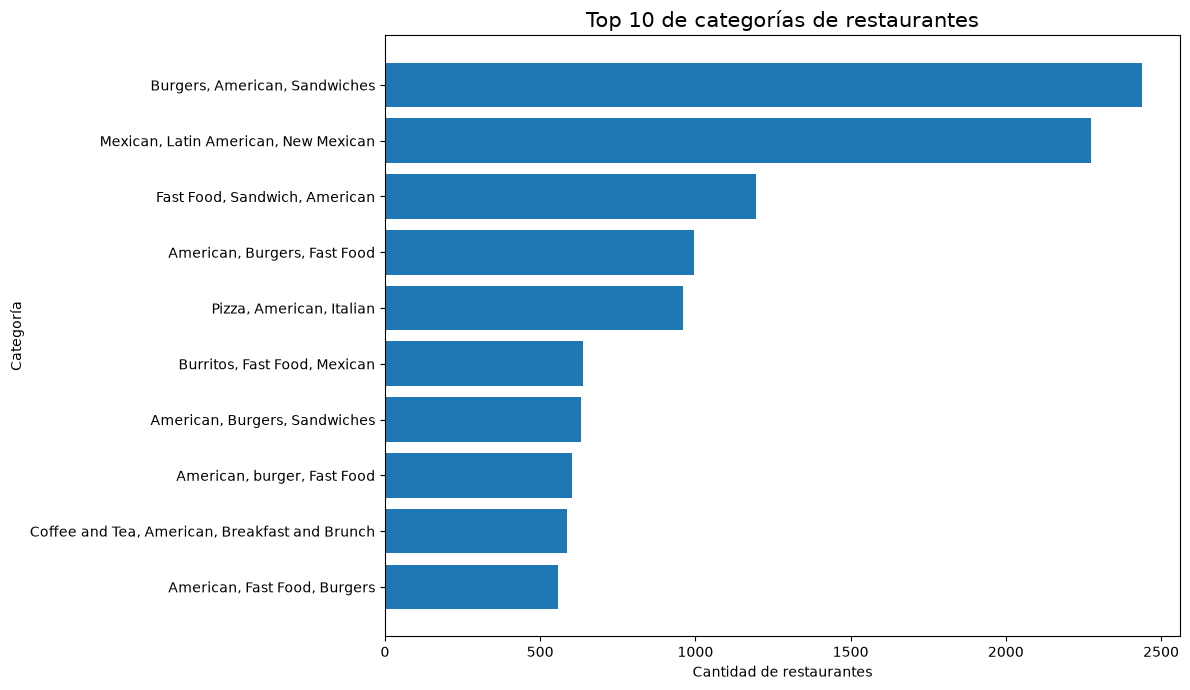

Porcentaje de precios superiores a US$ 50: 0.79 %


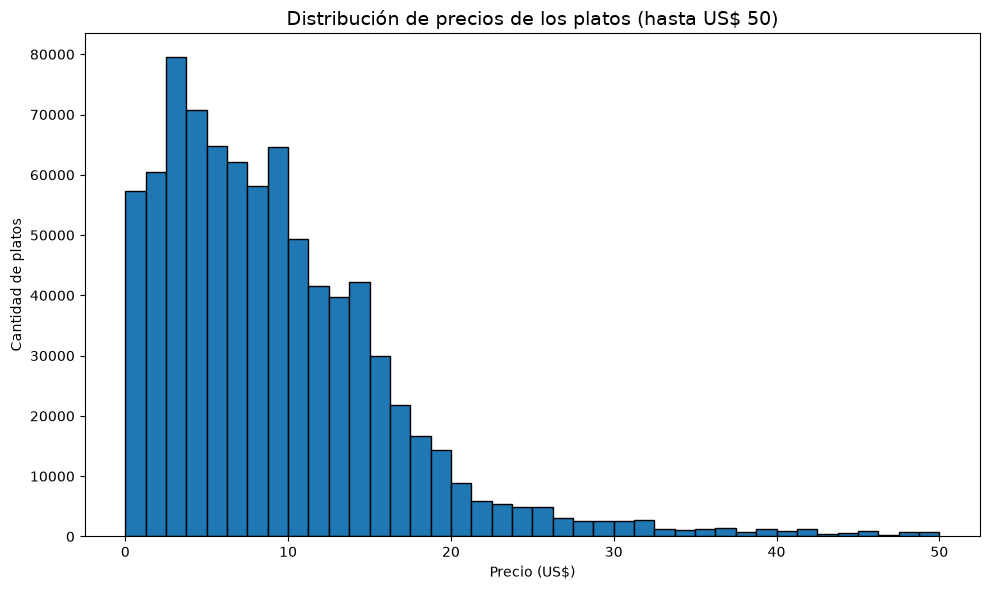

In [14]:
import matplotlib.pyplot as plt

# Gráfico 1: Top 10 de categorías de restaurantes
plt.figure(figsize=(12, 7))

categorias_grafico = df_categorias.sort_values(
    "cantidad_restaurantes",
    ascending=True
)

plt.barh(
    categorias_grafico["category"],
    categorias_grafico["cantidad_restaurantes"]
)

plt.title("Top 10 de categorías de restaurantes", fontsize=15)
plt.xlabel("Cantidad de restaurantes")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()


# Gráfico 2: Distribución de precios de los platos
# Se limita a precios de hasta US$ 50 para visualizar mejor
# el rango habitual sin que los valores extremos compriman el gráfico.

precios_validos = df_menus_limpio["price_usd"].dropna()
precios_hasta_50 = precios_validos[precios_validos <= 50]

print(
    "Porcentaje de precios superiores a US$ 50:",
    round((precios_validos > 50).mean() * 100, 2),
    "%"
)

plt.figure(figsize=(10, 6))

plt.hist(
    precios_hasta_50,
    bins=40,
    edgecolor="black"
)

plt.title("Distribución de precios de los platos (hasta US$ 50)", fontsize=14)
plt.xlabel("Precio (US$)")
plt.ylabel("Cantidad de platos")
plt.tight_layout()
plt.show()


## 11. Conclusiones y recomendaciones de negocio

### Principales hallazgos

1. **Volumen de información:** se integraron 836,350 registros de menús provenientes de diez archivos CSV y se identificaron 63,469 restaurantes.

2. **Calidad de la integración:** el 100% de los registros de menús encontró un restaurante asociado mediante su identificador.

3. **Precios:** el precio promedio de los platos es de US$ 9.90 y la mediana es de US$ 7.99. La diferencia entre ambos indicadores sugiere que los precios elevados influyen en el promedio.

4. **Categorías:** las combinaciones de categorías más frecuentes están relacionadas con hamburguesas, comida americana, comida rápida y comida mexicana.

5. **Distribución de precios:** el 0.79% de los registros presenta precios superiores a US$ 50. Estos valores merecen una revisión adicional para distinguir productos especiales, posibles errores y precios legítimamente elevados.

### Recomendaciones

- Analizar la demanda y la competencia por categoría antes de priorizar nuevas alianzas con restaurantes.
- Utilizar la mediana como complemento del promedio al evaluar precios típicos.
- Revisar los valores extremos y los registros con datos faltantes antes de realizar análisis más avanzados.
- Incorporar indicadores por restaurante, categoría y rango de precios para facilitar futuras decisiones comerciales.

### Limitaciones

El análisis describe los datos disponibles. La cantidad de restaurantes por categoría no demuestra por sí sola la demanda de los consumidores, y los precios del menú no representan necesariamente el importe final pagado por un cliente.